# Лабораторная работа 2: Исследование зависимости между случайными величинами с помощью ВЧКК и ВМКК.

1. По результатам выполнения задания 3.2.1 найти значения ВЧКК `r_{1,2|3}` и `r_{1,3|2}`. Сравнить полученные значения с соответствующими оценками `r_{1,2}` и `r_{1,3}` для парных коэффициентов корреляции.
   * Что можно сказать о статистической значимости ВЧКК и ВКК?
   * Что является причиной корреляции между анализируемыми случайными величинами: непосредственная связь между ними или влияние третьего фактора?
2. По результатам выполнения задания 3.2.2 найти значение ВМКК `r_{1,2,3}`. Сравнить полученное значение:
   * а) с величиной `R` (где `R^2` — коэффициент детерминации для модели множественной линейной регрессии `x_1` на `x_{(2)}`);  
   * б) с оценкой МКК, вычисляемой в разделе “Корреляционный анализ” компьютерного учебника.  
   * Что можно сказать о статистической значимости полученного значения ВМКК?  
3. Провести аналогичные исследования с альтернативными ППП. Сравнить полученные результаты.  

### Указания:
- Исследование проводить по индивидуальным наборам данных для указанных переменных и выборок.
- Описание данных см. в прилагаемом файле.

Король Денис, 3 курс, 8а группа
Вариант: type 3, "sepalwid"

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as sts

In [2]:
data = pd.read_excel('irisdat.xlsx')
print(data.shape)
data.head(3)

(150, 5)


,sepallen,sepalwid,petallen,petalwid,type
0,5.0,3.3,1.4,0.2,1
1,6.4,2.8,5.6,2.2,3
2,6.5,2.8,4.6,1.5,2


In [3]:
data['type'].unique()

array([1, 3, 2])

In [4]:
data.isna()

,sepallen,sepalwid,petallen,petalwid,type
0,False,False,False,False,False
1,False,False,False,False,False
2,False,False,False,False,False
3,False,False,False,False,False
4,False,False,False,False,False
...,...,...,...,...,...
145,False,False,False,False,False
146,False,False,False,False,False
147,False,False,False,False,False
148,False,False,False,False,False


In [5]:
data.isna().sum(axis=0)

sepallen    0
sepalwid    0
petallen    0
petalwid    0
type        0
dtype: int64

In [6]:
#вариант 6: type = 3, sepalwid, sepallen, petalwid

In [7]:
x1 = data[data['type'] == 3]['sepalwid'].values
x2 = data[data['type'] == 3]['sepallen'].values
x3 = data[data['type'] == 3]['petalwid'].values
print(x1.shape)
print(x2.shape)
print(x3.shape)
x1[:6], x2[:6], x3[:6]

(50,)
(50,)
(50,)


(array([2.8, 3.1, 2.8, 3.1, 3. , 3. ]),
 array([6.4, 6.7, 6.3, 6.9, 6.5, 6.5]),
 array([2.2, 2.4, 1.5, 2.3, 2. , 1.8]))

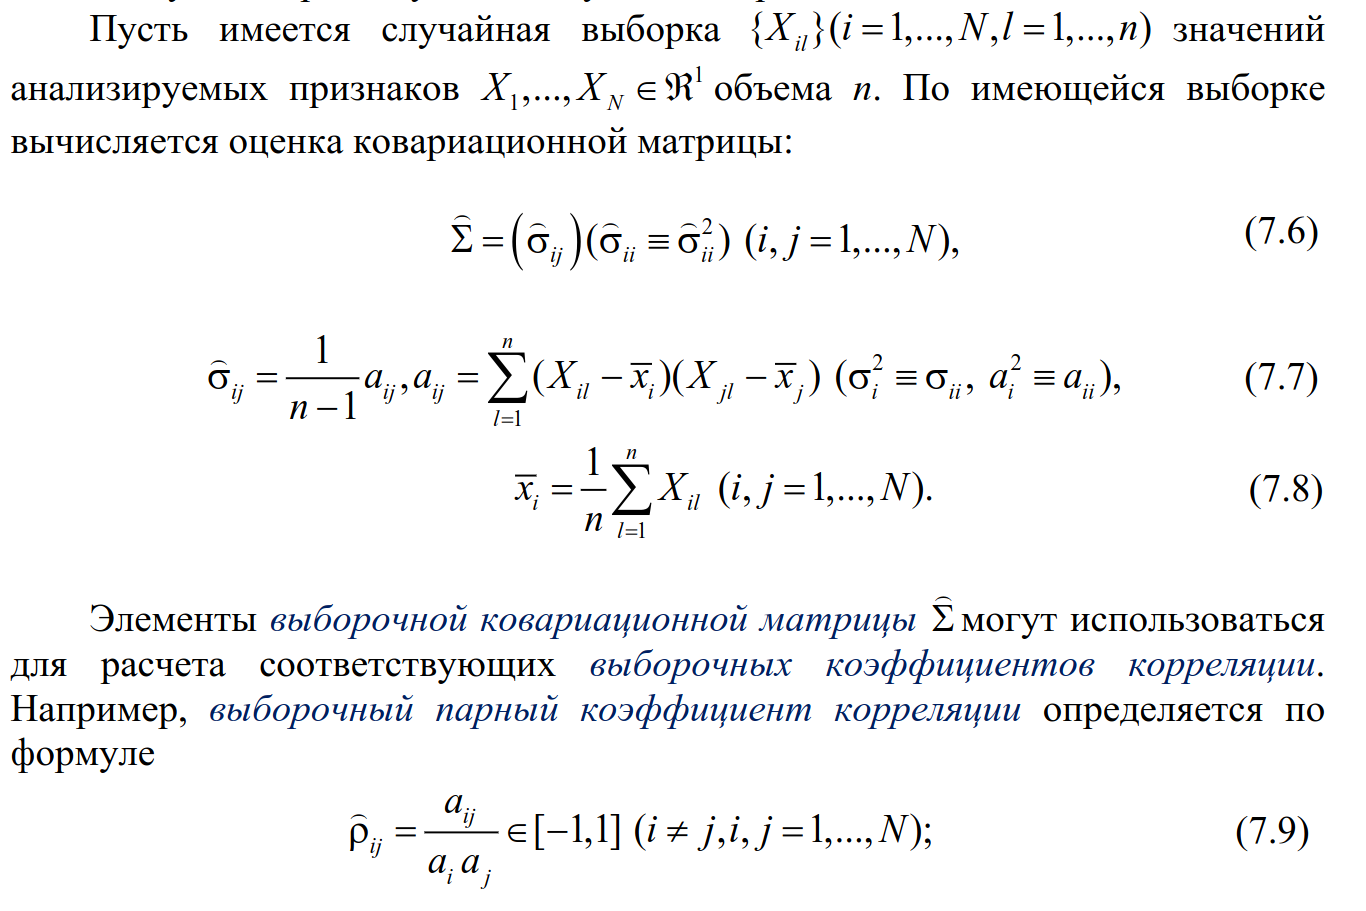

In [8]:
mean_val_1 = x1.mean().item()
mean_val_2 = x2.mean().item()
mean_val_3 = x3.mean().item()

print(f"Среднее sepalwid: {mean_val_1:.4f}")
print(f"Среднее sepallen: {mean_val_2:.4f}")
print(f"Среднее petalwid: {mean_val_3:.4f}")

Среднее sepalwid: 2.9740
Среднее sepallen: 6.5880
Среднее petalwid: 2.0260


In [9]:
a_11 = np.sum((x1 - mean_val_1)**2)
a_22 = np.sum((x2 - mean_val_2)**2)
a_33 = np.sum((x3 - mean_val_3)**2)

a_11, a_22, a_33

(np.float64(5.096199999999999),
 np.float64(19.812800000000003),
 np.float64(3.696199999999999))

In [10]:
a_1 = np.sqrt(a_11)
a_2 = np.sqrt(a_22)
a_3 = np.sqrt(a_33)

a_1, a_2, a_3

(np.float64(2.257476467208462),
 np.float64(4.4511571529210245),
 np.float64(1.9225503894566713))

In [11]:
a_12 = np.sum((x1 - mean_val_1)*(x2 - mean_val_2))
a_23 = np.sum((x2 - mean_val_2)*(x3 - mean_val_3))
a_13 = np.sum((x3 - mean_val_3)*(x1 - mean_val_1))

a_12, a_23, a_13

(np.float64(4.594399999999999),
 np.float64(2.405600000000001),
 np.float64(2.3338))

In [12]:
r_12 = a_12 / (a_1 * a_2)
r_23 = a_23 / (a_2 * a_3)
r_13 = a_13 / (a_1 * a_3)

r_12, r_23, r_13

(np.float64(0.457227816394113),
 np.float64(0.2811077091573194),
 np.float64(0.5377280262661889))

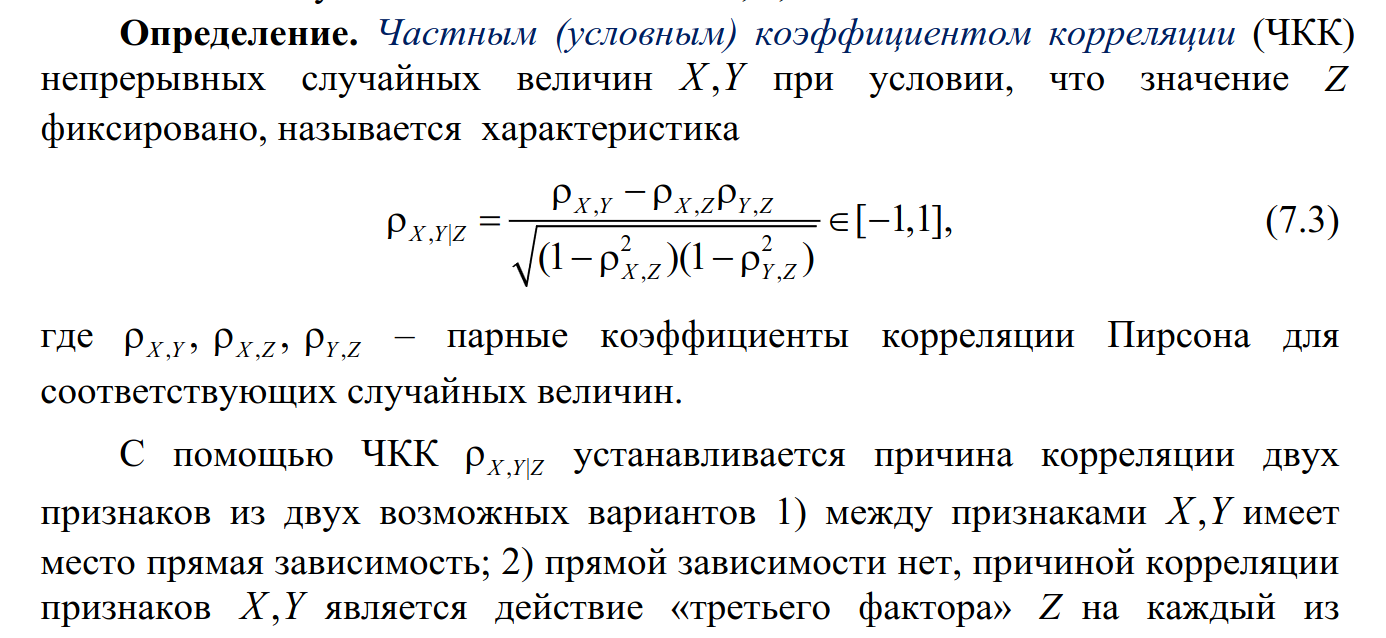
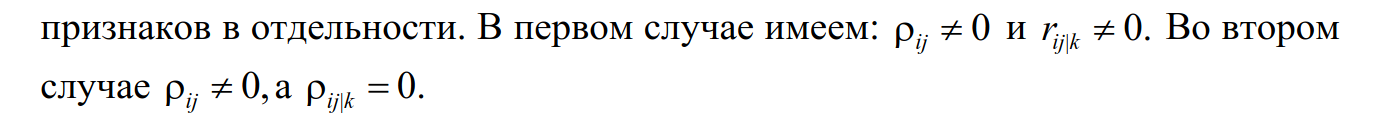

In [13]:
r_12_3 = (r_12 - r_13 * r_23)/np.sqrt((1 - r_13**2) * (1 - r_23**2))
r_23_1 = (r_23 - r_12 * r_13)/np.sqrt((1 - r_12**2) * (1 - r_13**2))
r_13_2 = (r_13 - r_12 * r_23)/np.sqrt((1 - r_12**2) * (1 - r_23**2))

r_12_3, r_23_1, r_13_2

(np.float64(0.37827278871255676),
 np.float64(0.04700217344052275),
 np.float64(0.4794419123083884))

r_12_3, r_23_1, r_13_2 != 0 --> имеет место прямая зависимость

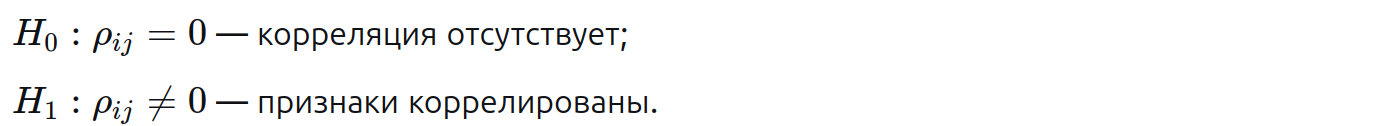
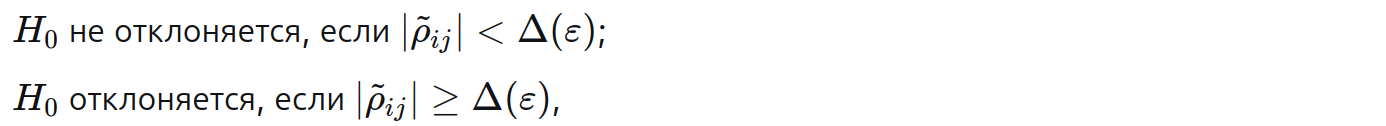

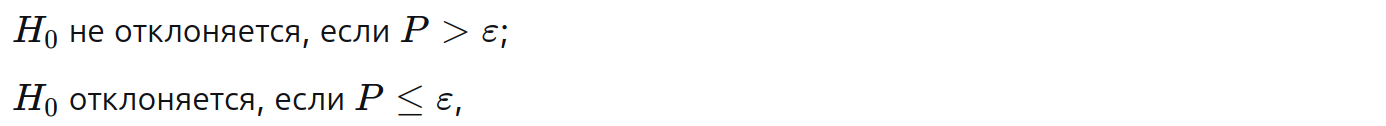
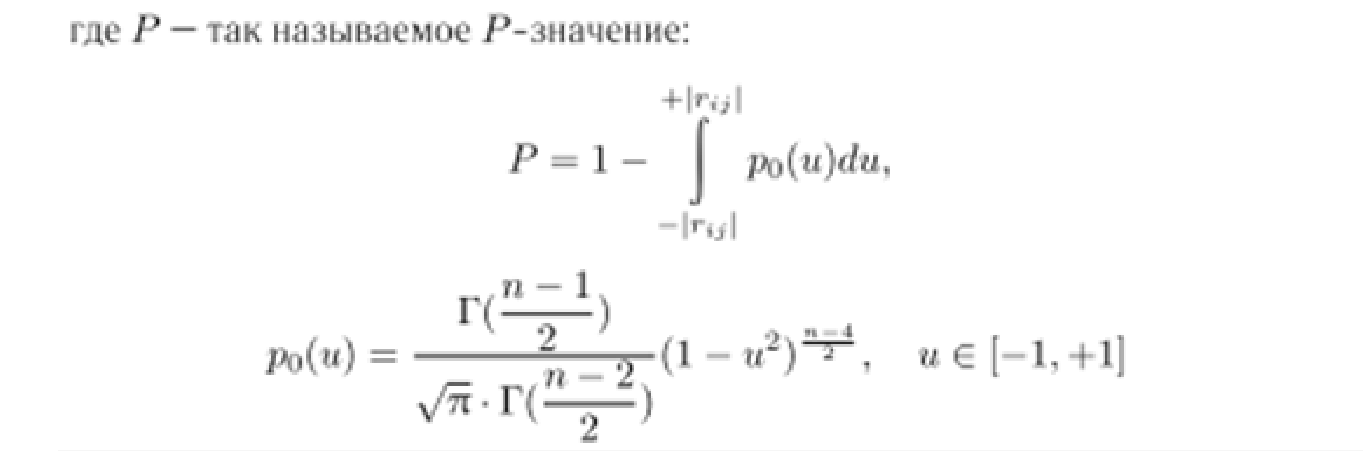

Практически это то же самое, что t-критерий Стьюдента с n−2 степенями свободы:

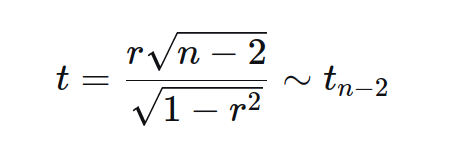